In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/, so go up one level to reach the project root
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text
from src import config as C

engine = C.get_engine()

# Pull raw daily sales from MySQL. Doing the aggregation in SQL keeps pandas light.
daily = pd.read_sql(text("SELECT date, store, item, units FROM sales"), engine,
                    parse_dates=["date"])
print(daily.shape)
daily.head()

(913000, 4)


,date,store,item,units
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [2]:
print("Missing values:\n", daily.isna().sum(), "\n")
print("Zero-sales rows:", (daily["units"] == 0).sum())
print(daily["units"].describe())

# Completeness: every store-item should have one row per day (1826 days in 2013-2017)
counts = daily.groupby(["store", "item"]).size()
print("\nRows per store-item: min", counts.min(), "max", counts.max())

Missing values:
 date     0
store    0
item     0
units    0
dtype: int64 

Zero-sales rows: 1
count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: units, dtype: float64

Rows per store-item: min 1826 max 1826


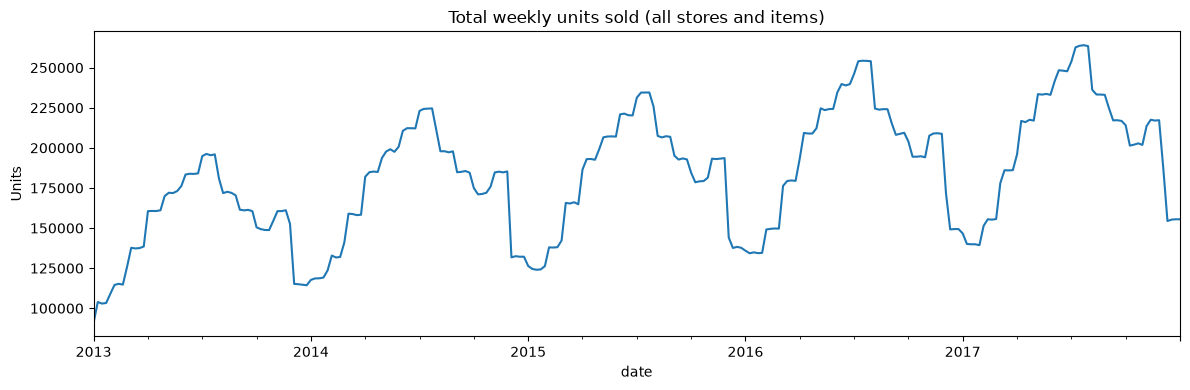

In [3]:
OUT = C.OUT_DIR
OUT.mkdir(exist_ok=True)

weekly = daily.set_index("date")["units"].resample("W").sum()

fig, ax = plt.subplots(figsize=(12, 4))
weekly.plot(ax=ax)
ax.set_title("Total weekly units sold (all stores and items)")
ax.set_ylabel("Units")
plt.tight_layout()
plt.savefig(OUT / "01_weekly_total.png", dpi=150)
plt.show()

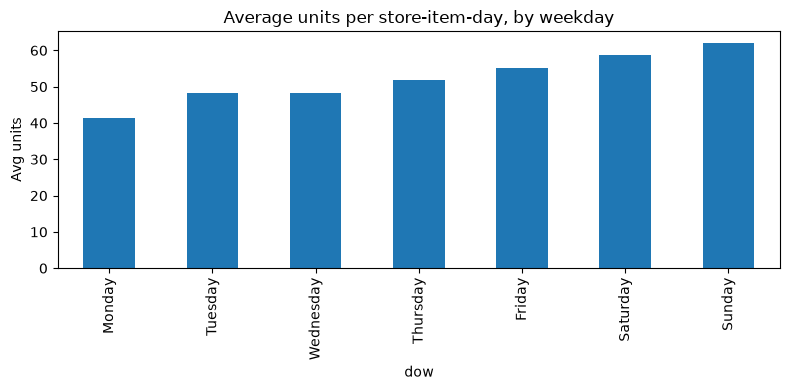

dow
Monday       0.000
Tuesday      0.164
Wednesday    0.167
Thursday     0.248
Friday       0.331
Saturday     0.416
Sunday       0.500
Name: units, dtype: float64


In [6]:
daily["dow"] = daily["date"].dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = daily.groupby("dow")["units"].mean().reindex(order)

fig, ax = plt.subplots(figsize=(8, 4))
dow.plot.bar(ax=ax)
ax.set_title("Average units per store-item-day, by weekday")
ax.set_ylabel("Avg units")
plt.tight_layout()
plt.savefig(OUT / "02_day_of_week.png", dpi=150)
plt.show()
print((dow / dow.min() - 1).round(3))

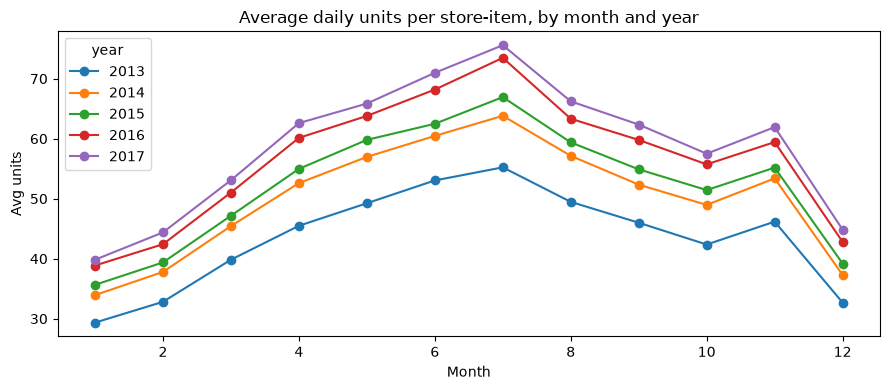

In [5]:
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
monthly = daily.groupby(["year", "month"])["units"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o")
ax.set_title("Average daily units per store-item, by month and year")
ax.set_xlabel("Month")
ax.set_ylabel("Avg units")
plt.tight_layout()
plt.savefig(OUT / "03_monthly_by_year.png", dpi=150)
plt.show()